# Sweeping the Lines of a Clay Tennis Court

*© 2026 Taras Bulubas — all rights reserved. You may open, run and modify this
notebook in Google Colab for personal, non-commercial exploration; any other
use requires prior written permission. See `LICENSE`.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/tbulubas/tennis-line-sweeping/blob/main/notebooks/line_sweeping.ipynb)

This notebook plans how to sweep the lines of one half of a clay tennis court
as quickly as possible: where to start, in which order and direction to sweep
the lines, and where to lift and carry the broom. It explains the problem and
the mathematical model, lets you change the input, solves the model with
**OR-Tools + SCIP** and draws the optimal route.

**How to use it**

1. Run all cells once: *Run → Run All Cells* (in Google Colab: *Runtime →
   Run all*).
2. Change the numbers in [section 4](#4-input-parameters) and run the cells
   from there on again, or use the interactive explorer in
   [section 8](#8-interactive-explorer).

**Where it runs**

- **Google Colab** — open it with the badge above. The first code cell
  installs the model package from GitHub (about half a minute). Your changes
  stay in your own copy; save it to your Google Drive with *File → Save a
  copy in Drive* if you want to keep them.
- **Locally** — in the project's Python environment (`.venv`), which already
  contains the package; the install step is skipped.

**Contents**

1. [The problem](#1-the-problem)
2. [The model](#2-the-model)
3. [Setup](#3-setup)
4. [Input parameters](#4-input-parameters)
5. [Solve](#5-solve)
6. [The route](#6-the-route)
7. [Why the route is optimal](#7-why-the-route-is-optimal)
8. [Interactive explorer](#8-interactive-explorer)
9. [Things to try](#9-things-to-try)

## 1. The problem

The lines of a clay court are tapes in the clay; after play they are swept
with a line broom. The broom is kept somewhere by the fence, at a place
**B**.

Only **one half** of the court is swept — one player's side — with **all**
its lines, doubles lines included. The court has the standard ITF
dimensions: half court 11.885 m deep, doubles width 10.97 m, singles width
8.23 m, service line 6.40 m from the net, centre mark 0.10 m. Together the
lines are **73.24 m** long.

```
          net  ─────────────────────────────────────────────
   N0 ●───N1 ●───────────────── NC ●──────────────── N2 ●───● N3
      │      │                     │                   │      │
      │   S1 ●─────────────────── SC ●────────────── S2 ●      │
      │      │                                         │      │
   B0 ●───B1 ●───────────────── BC ●──────────────── B2 ●───● B3
                                   ╹ centre mark
```

Coordinates: origin at the left end of the baseline (B0), seen from behind
the baseline; x to the right, y towards the net.

### Rules

1. Start at B by picking up the broom; end by putting it back at B.
2. Carry the broom to a corner, a junction or a line end and start sweeping.
3. A **run** follows the lines without lifting the broom; it may turn at
   corners and junctions.
4. Every part of every line is swept **exactly once**.
5. Between runs the broom is lifted and carried in a straight line to the
   start of the next run.

### Goal

**Minimise the total time** = length swept / $v_s$ + length carried / $v_c$.
In iteration 1 both speeds are equal.

Sweeping takes the same time in every plan — every line is swept exactly
once. The plan decides how often and how far the broom is carried. Where an
odd number of line pieces meet (the six junctions and the six line ends), a
run must start or end, so every plan has **at least 6 runs**.

## 2. The model

### Idea

The stop points are the **vertices** of a graph, the line pieces between them
its **segments**; the broom place $B$ is one more node. A route sweeps every
segment once in some direction and carries the broom straight between nodes
in between. As a directed multigraph — one arc per swept segment, one arc
per carry — the route is an **Euler circuit** through $B$.

A connected directed multigraph has an Euler circuit exactly when every node
is left as often as it is reached. The lines are connected, so the model
only chooses the sweeping directions and the carries so that every node is
balanced. The order of the moves is found afterwards with Hierholzer's
algorithm.

### Variables

| Variable | Domain | Meaning |
|---|---|---|
| $s_e$ | $\{0,1\}$ | segment $e = \{u, v\}$ is swept $u \to v$ (1) or $v \to u$ (0) |
| $w_{ab}$ | $\{0,1\}$ | the broom is carried straight from node $a$ to node $b$ |

$S^+_v, S^-_v$ count the sweeps leaving and reaching vertex $v$ (linear in
$s$), $C^+_a = \sum_b w_{ab}$ and $C^-_a = \sum_b w_{ba}$ the carries.

### Constraints

$$S^+_v + C^+_v = S^-_v + C^-_v \qquad \forall v \quad \text{(1: balance)}$$

$$C^+_B = 1, \quad C^-_B = 1 \qquad \text{(2: pick up and put back once)}$$

$$C^+_v + C^-_v \ge 1 \qquad \forall v \text{ of odd degree} \quad \text{(3: a run starts or ends here)}$$

$$w_{ab} + w_{ba} \le 1 \qquad \text{(4: never carry back and forth)}$$

### Objective

$$\min \; \sum_e \frac{\ell_e}{v_s} \;+\; \sum_{a,b} \frac{c_{ab}}{v_c}\, w_{ab}$$

with $\ell_e$ the segment lengths and $c_{ab}$ the straight-line distances.
The first sum is a constant.

## 3. Setup

The first cell installs the `line_sweeping` package with the model from GitHub
if it is not available yet (e.g. in Google Colab). The second cell imports it.

In [1]:
import importlib
import importlib.util
import subprocess
import sys

REPOSITORY = "https://github.com/tbulubas/tennis-line-sweeping.git"

if importlib.util.find_spec("line_sweeping") is None:
    print("Installing the line_sweeping package from GitHub …")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "--quiet", f"line-sweeping[plot] @ git+{REPOSITORY}"]
    )
    importlib.invalidate_caches()
    print("done")
else:
    print("line_sweeping is already installed")

line_sweeping is already installed


In [2]:
import sys
import time
from functools import cache

import pandas as pd
from IPython.display import Markdown, display

import ortools
from line_sweeping import MoveKind, Status, SweepInstance, solve, verify
from line_sweeping.court import distance
from line_sweeping.draw import plot_plan
from line_sweeping.model import model_size

print(f"Python {sys.version.split()[0]}  ·  OR-Tools {ortools.__version__}")

Python 3.12.10  ·  OR-Tools 9.15.6755


## 4. Input parameters

Change the values and re-run this cell and all cells below it
(*Run → Run Selected Cell and All Below*). Positions are in metres in court
coordinates, speeds in metres per second.

In [3]:
BROOM_X = 5.485       # broom place, x: 0 = left doubles sideline, 10.97 = right one
BROOM_Y = -6.40       # broom place, y: 0 = baseline, 11.885 = net; -6.40 = back fence
SWEEP_SPEED = 1.0     # walking speed while sweeping [m/s]
CARRY_SPEED = 1.0     # walking speed while carrying the lifted broom [m/s]
TIME_LIMIT_S = 60     # solver time limit in seconds (None = no limit)

instance = SweepInstance(broom=(BROOM_X, BROOM_Y), sweep_speed=SWEEP_SPEED, carry_speed=CARRY_SPEED)
instance

SweepInstance(broom=(5.485, -6.4), sweep_speed=1.0, carry_speed=1.0, court=CourtDimensions(length=23.77, doubles_width=10.97, singles_width=8.23, service_line_distance=6.4, centre_mark_length=0.1))

## 5. Solve

In [4]:
start = time.perf_counter()
plan = solve(instance, time_limit_s=TIME_LIMIT_S)
elapsed = time.perf_counter() - start
print(f"status: {plan.status.value}   ·   solved in {elapsed:.2f} s")

status: optimal   ·   solved in 0.01 s


## 6. The route

The drawing shows the half court from above with the net at the top. Each
run has its number at its start; runs share one colour that gets darker from
the first run to the last, and arrows show the sweeping direction. Dashed
arrows are the carries of the lifted broom (drawn slightly curved so that
they stay visible where they run along a line).

**Optimal route: 103.02 s** = sweeping 73.24 s + carrying 29.78 s.  
6 runs (at least 6); 73.24 m swept, 29.78 m carried.

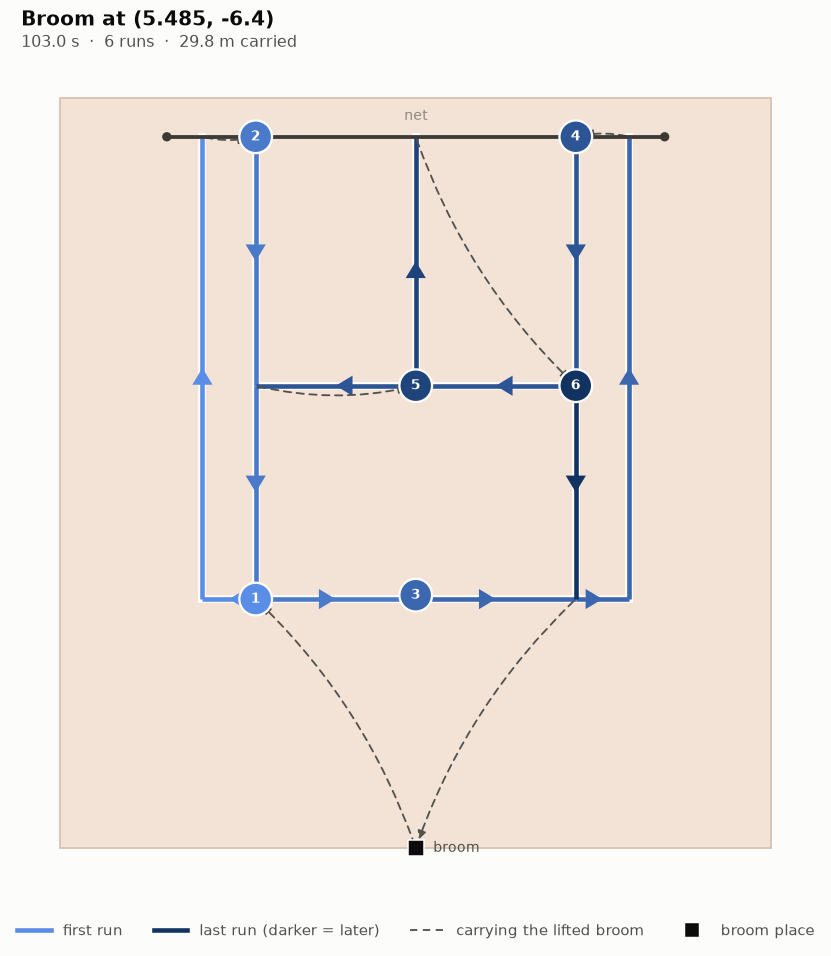

In [5]:
def describe(instance, plan):
    if not plan.has_plan:
        return Markdown(f"**No plan ({plan.status.value}).** Increase TIME_LIMIT_S.")
    carry_time = plan.carry_distance / instance.carry_speed
    return Markdown(
        f"**{plan.status.value.capitalize()} route: {plan.objective:.2f} s** = "
        f"sweeping {instance.sweep_time:.2f} s + carrying {carry_time:.2f} s.  \n"
        f"{len(plan.runs)} runs (at least {instance.min_runs}); "
        f"{plan.sweep_distance:.2f} m swept, {plan.carry_distance:.2f} m carried."
    )


def note(instance, plan):
    return f"{plan.objective:.1f} s  ·  {len(plan.runs)} runs  ·  {plan.carry_distance:.1f} m carried"


display(describe(instance, plan))
if plan.has_plan:
    display(plot_plan(instance, plan, title=f"Broom at ({BROOM_X:g}, {BROOM_Y:g})", note=note(instance, plan)))

### The route step by step

In [6]:
def route_table(instance, plan):
    rows, run = [], 0
    previous = MoveKind.CARRY
    for move in plan.moves:
        if move.kind == MoveKind.SWEEP and previous == MoveKind.CARRY:
            run += 1
        speed = instance.sweep_speed if move.kind == MoveKind.SWEEP else instance.carry_speed
        rows.append({
            "run": run if move.kind == MoveKind.SWEEP else "",
            "move": move.kind.value,
            "from": f"({move.start[0]:.3f}, {move.start[1]:.3f})",
            "to": f"({move.end[0]:.3f}, {move.end[1]:.3f})",
            "line": move.line or "",
            "length [m]": round(move.length, 3),
            "time [s]": round(move.length / speed, 2),
        })
        previous = move.kind
    return pd.DataFrame(rows, index=pd.RangeIndex(1, len(rows) + 1, name="step"))


if plan.has_plan:
    display(route_table(instance, plan))

,run,move,from,to,line,length [m],time [s]
step,,,,,,,
1,,carry,"(5.485, -6.400)","(1.370, 0.000)",,7.609,7.61
2,1,sweep,"(1.370, 0.000)","(0.000, 0.000)",baseline,1.370,1.37
3,1,sweep,"(0.000, 0.000)","(0.000, 11.885)",left doubles sideline,11.885,11.88
4,,carry,"(0.000, 11.885)","(1.370, 11.885)",,1.370,1.37
5,2,sweep,"(1.370, 11.885)","(1.370, 5.485)",left singles sideline,6.400,6.40
6,2,sweep,"(1.370, 5.485)","(1.370, 0.000)",left singles sideline,5.485,5.48
7,2,sweep,"(1.370, 0.000)","(5.485, 0.000)",baseline,4.115,4.12
8,,carry,"(5.485, 0.000)","(5.485, 0.100)",,0.100,0.10
9,3,sweep,"(5.485, 0.100)","(5.485, 0.000)",centre mark,0.100,0.10


### Independent check

`verify` checks the route against the rules using only positions and the
painted lines — it does not look at the model. An empty list means every
rule is satisfied.

In [7]:
verify(instance, plan) if plan.has_plan else "no plan to check"

[]

## 7. Why the route is optimal

SCIP proves optimality of the MILP. As a cross-check, the optimum can also be
computed without the model: the broom place is joined to two vertices $u$ and
$v$ (possibly $u = v$), and the other carries pair up the remaining vertices
of odd degree — a **minimum perfect matching**, found here by dynamic
programming over subsets. Both numbers must agree.

In [8]:
def optimal_carry_distance(instance):
    graph = instance.graph
    points = [v.point for v in graph.vertices]
    odd = frozenset(graph.odd_vertices)

    @cache
    def matching(rest):
        if not rest:
            return 0.0
        first, *others = sorted(rest)
        return min(distance(points[first], points[k]) + matching(rest - {first, k}) for k in others)

    return min(
        distance(instance.broom, points[u]) + distance(instance.broom, points[v])
        + matching(odd ^ {u} ^ {v} if u != v else odd)
        for u in range(len(points)) for v in range(u, len(points))
    )


check = pd.DataFrame(
    {"carrying distance [m]": [plan.carry_distance, optimal_carry_distance(instance)]},
    index=["MILP route", "matching (independent)"],
).round(4)
display(check)
display(Markdown("**Model size:**"))
display(pd.Series(model_size(instance), name="count").to_frame())

,carrying distance [m]
MILP route,29.7813
matching (independent),29.7813


**Model size:**

,count
vertices,14
segments,14
binary variables s,14
binary variables w,210
constraints,119


## 8. Interactive explorer

Move the sliders and press **Solve**. This needs a running kernel (it does
not work in a static view of the notebook). The broom may stand anywhere,
also on the court.

In [9]:
import ipywidgets as w

style = {"description_width": "230px"}
layout = w.Layout(width="620px")


def slider(description, value, lo, hi, step):
    return w.FloatSlider(value=value, min=lo, max=hi, step=step, description=description,
                         style=style, layout=layout, continuous_update=False)


controls = {
    "x": slider("broom x [m]", BROOM_X, -5.0, 16.0, 0.1),
    "y": slider("broom y [m]", BROOM_Y, -8.0, 13.0, 0.1),
    "sweep_speed": slider("v_s — sweeping speed [m/s]", SWEEP_SPEED, 0.2, 3.0, 0.1),
    "carry_speed": slider("v_c — carrying speed [m/s]", CARRY_SPEED, 0.2, 3.0, 0.1),
}
button = w.Button(description="Solve", button_style="primary", icon="play")
output = w.Output()


def on_solve(_):
    with output:
        output.clear_output(wait=True)
        values = {key: c.value for key, c in controls.items()}
        inst = SweepInstance(broom=(values["x"], values["y"]), sweep_speed=values["sweep_speed"],
                             carry_speed=values["carry_speed"])
        t0 = time.perf_counter()
        result = solve(inst, time_limit_s=TIME_LIMIT_S)
        display(describe(inst, result))
        if result.has_plan:
            display(plot_plan(inst, result, title=f"Broom at ({values['x']:g}, {values['y']:g})",
                              note=note(inst, result)))
        print(f"solved in {time.perf_counter() - t0:.2f} s")


button.on_click(on_solve)
display(w.VBox([*controls.values(), button, output]))

## 9. Things to try

Set the values in [section 4](#4-input-parameters) (or with the sliders) and
watch how the route changes.

| Try | What happens |
|---|---|
| broom at $(5.485, -6.40)$, back fence | 6 runs, 29.78 m carried, 103.02 s in total. |
| broom at $(-3.66, 11.0)$, side fence by the net | The route starts and ends by the net, near the broom: 27.71 m carried, 100.95 s. |
| broom at $(0, 0)$, on the left corner | The carries to and from the broom shrink to the walk to the nearest stop points. |
| broom far away, e.g. $(20, 30)$ | The first and the last run start and end at the stop points nearest to the broom. |
| $v_c = 2$ m/s | Same route, carrying takes half the time: in iteration 1 the speeds do not change the route. |